# Milestone 5

Saebastion Cole

11/22/2026

DSC540-T301

For this assignment I am going to take everything I did for the previous assignments and combine them adding them to the SqlLite database table. Then do analysis on the data.

In [389]:
# Imports
import re
import sqlite3

import pandas as pd
import numpy as np
import requests
from bs4 import BeautifulSoup
from requests.adapters import HTTPAdapter
from urllib3.util.retry import Retry

## Load File (CSV) based data

In [390]:
# Open the file
country_list = pd.read_csv("data/ISO-3166Countries.csv", dtype=str, keep_default_na=False, na_values=[''])


In [391]:
# Normalize the column names
# First data manipulation: fix column headers to all kebab casing
# I saw one of the column headers used underscores instead of hyphens.
country_list.columns = country_list.columns.str.replace('_', '-')
country_list.head()

,name,alpha-2,alpha-3,country-code,iso-3166-2,region,sub-region,intermediate-region,region-code,sub-region-code,intermediate-region-code
0,Afghanistan,AF,AFG,004,ISO 3166-2:AF,Asia,Southern Asia,NaN,142,034,NaN
1,Åland Islands,AX,ALA,248,ISO 3166-2:AX,Europe,Northern Europe,NaN,150,154,NaN
2,Albania,AL,ALB,008,ISO 3166-2:AL,Europe,Southern Europe,NaN,150,039,NaN
3,Algeria,DZ,DZA,012,ISO 3166-2:DZ,Africa,Northern Africa,NaN,002,015,NaN
4,American Samoa,AS,ASM,016,ISO 3166-2:AS,Oceania,Polynesia,NaN,009,061,NaN


In [392]:
# Clean region column if empty pad it
# Now I will fix the intermediate region code to default the values removing the NaN
print(f"Missing before: {country_list['intermediate-region-code'].isna().sum()}")

country_list['intermediate-region-code'] = country_list['intermediate-region-code'].fillna('000')

country_list.head()

Missing before: 144


,name,alpha-2,alpha-3,country-code,iso-3166-2,region,sub-region,intermediate-region,region-code,sub-region-code,intermediate-region-code
0,Afghanistan,AF,AFG,004,ISO 3166-2:AF,Asia,Southern Asia,NaN,142,034,000
1,Åland Islands,AX,ALA,248,ISO 3166-2:AX,Europe,Northern Europe,NaN,150,154,000
2,Albania,AL,ALB,008,ISO 3166-2:AL,Europe,Southern Europe,NaN,150,039,000
3,Algeria,DZ,DZA,012,ISO 3166-2:DZ,Africa,Northern Africa,NaN,002,015,000
4,American Samoa,AS,ASM,016,ISO 3166-2:AS,Oceania,Polynesia,NaN,009,061,000


In [393]:
# Fix regions to not be empty
# Now similarly I will fix the region code to default the values removing the NaN

country_list['intermediate-region'] = country_list['intermediate-region'].fillna('None')
  
country_list.head()

,name,alpha-2,alpha-3,country-code,iso-3166-2,region,sub-region,intermediate-region,region-code,sub-region-code,intermediate-region-code
0,Afghanistan,AF,AFG,004,ISO 3166-2:AF,Asia,Southern Asia,None,142,034,000
1,Åland Islands,AX,ALA,248,ISO 3166-2:AX,Europe,Northern Europe,None,150,154,000
2,Albania,AL,ALB,008,ISO 3166-2:AL,Europe,Southern Europe,None,150,039,000
3,Algeria,DZ,DZA,012,ISO 3166-2:DZ,Africa,Northern Africa,None,002,015,000
4,American Samoa,AS,ASM,016,ISO 3166-2:AS,Oceania,Polynesia,None,009,061,000


In [394]:
# Reorder the data
# Reorder the columns to make it easier to read
country_list = country_list[[
    'name', 'alpha-2', 'alpha-3', 'country-code',
    'iso-3166-2', 'region', 'region-code',
    'sub-region', 'sub-region-code',
    'intermediate-region', 'intermediate-region-code',
]]

country_list.head()

,name,alpha-2,alpha-3,country-code,iso-3166-2,region,region-code,sub-region,sub-region-code,intermediate-region,intermediate-region-code
0,Afghanistan,AF,AFG,004,ISO 3166-2:AF,Asia,142,Southern Asia,034,None,000
1,Åland Islands,AX,ALA,248,ISO 3166-2:AX,Europe,150,Northern Europe,154,None,000
2,Albania,AL,ALB,008,ISO 3166-2:AL,Europe,150,Southern Europe,039,None,000
3,Algeria,DZ,DZA,012,ISO 3166-2:DZ,Africa,002,Northern Africa,015,None,000
4,American Samoa,AS,ASM,016,ISO 3166-2:AS,Oceania,009,Polynesia,061,None,000


In [395]:
# Add a cleaned country name column (This can be used for fuzzy matching)
# Make a column with a cleansed version of the country name. 
country_list['name-cleansed'] = country_list['name'].str.split(",").str[0]  # Remove any text after a comma


country_list.loc[country_list['alpha-2'] == 'KR', 'name-cleansed'] = 'South Korea'
country_list.loc[country_list['alpha-2'] == 'KP', 'name-cleansed'] = 'North Korea'

country_list.head()

,name,alpha-2,alpha-3,country-code,iso-3166-2,region,region-code,sub-region,sub-region-code,intermediate-region,intermediate-region-code,name-cleansed
0,Afghanistan,AF,AFG,004,ISO 3166-2:AF,Asia,142,Southern Asia,034,None,000,Afghanistan
1,Åland Islands,AX,ALA,248,ISO 3166-2:AX,Europe,150,Northern Europe,154,None,000,Åland Islands
2,Albania,AL,ALB,008,ISO 3166-2:AL,Europe,150,Southern Europe,039,None,000,Albania
3,Algeria,DZ,DZA,012,ISO 3166-2:DZ,Africa,002,Northern Africa,015,None,000,Algeria
4,American Samoa,AS,ASM,016,ISO 3166-2:AS,Oceania,009,Polynesia,061,None,000,American Samoa


In [396]:
# Normalize the country names
# Now I am going to cleanup the name columns to remove any romoving accents and unique characters.

country_list['name-cleansed'] = country_list['name-cleansed'].str.normalize('NFKD').str.encode('ascii', errors='ignore').str.decode('ascii')
country_list

,name,alpha-2,alpha-3,country-code,iso-3166-2,region,region-code,sub-region,sub-region-code,intermediate-region,intermediate-region-code,name-cleansed
0,Afghanistan,AF,AFG,004,ISO 3166-2:AF,Asia,142,Southern Asia,034,None,000,Afghanistan
1,Åland Islands,AX,ALA,248,ISO 3166-2:AX,Europe,150,Northern Europe,154,None,000,Aland Islands
2,Albania,AL,ALB,008,ISO 3166-2:AL,Europe,150,Southern Europe,039,None,000,Albania
3,Algeria,DZ,DZA,012,ISO 3166-2:DZ,Africa,002,Northern Africa,015,None,000,Algeria
4,American Samoa,AS,ASM,016,ISO 3166-2:AS,Oceania,009,Polynesia,061,None,000,American Samoa
...,...,...,...,...,...,...,...,...,...,...,...,...
244,Wallis and Futuna,WF,WLF,876,ISO 3166-2:WF,Oceania,009,Polynesia,061,None,000,Wallis and Futuna
245,Western Sahara,EH,ESH,732,ISO 3166-2:EH,Africa,002,Northern Africa,015,None,000,Western Sahara
246,Yemen,YE,YEM,887,ISO 3166-2:YE,Asia,142,Western Asia,145,None,000,Yemen
247,Zambia,ZM,ZMB,894,ISO 3166-2:ZM,Africa,002,Sub-Saharan Africa,202,Eastern Africa,014,Zambia


### Load into the table

In [397]:
# Create the SQLite database and the countries table
# SQL column names can't contain hyphens without quoting, so the table uses snake_case versions of the country_list columns.
# Every code column is TEXT so leading zeros (e.g. "004") are kept.
conn = sqlite3.connect("data/milestone-5.db")
cur = conn.cursor()

cur.execute("DROP TABLE IF EXISTS countries")
cur.execute("""
CREATE TABLE countries (
    alpha_2                  TEXT PRIMARY KEY,
    name                     TEXT NOT NULL,
    alpha_3                  TEXT NOT NULL UNIQUE,
    country_code             TEXT NOT NULL UNIQUE,
    iso_3166_2               TEXT,
    region                   TEXT,
    region_code              TEXT,
    sub_region               TEXT,
    sub_region_code          TEXT,
    intermediate_region      TEXT,
    intermediate_region_code TEXT,
    name_cleansed            TEXT
)
""")
conn.commit()

In [398]:
# Insert the rows from country_list into the countries table
country_rows = country_list.rename(columns=lambda c: c.replace('-', '_'))
country_rows = country_rows.astype(object).where(country_rows.notna(), None)  # store missing values as NULL

columns = list(country_rows.columns)
placeholders = ", ".join("?" for _ in columns)
cur.executemany(
    f"INSERT INTO countries ({', '.join(columns)}) VALUES ({placeholders})",
    country_rows.itertuples(index=False, name=None),
)
conn.commit()

print(f"Rows inserted: {cur.execute('SELECT COUNT(*) FROM countries').fetchone()[0]}")
pd.read_sql_query("SELECT * FROM countries LIMIT 5", conn)

Rows inserted: 249


,alpha_2,name,alpha_3,country_code,iso_3166_2,region,region_code,sub_region,sub_region_code,intermediate_region,intermediate_region_code,name_cleansed
0,AF,Afghanistan,AFG,004,ISO 3166-2:AF,Asia,142,Southern Asia,034,None,000,Afghanistan
1,AX,Åland Islands,ALA,248,ISO 3166-2:AX,Europe,150,Northern Europe,154,None,000,Aland Islands
2,AL,Albania,ALB,008,ISO 3166-2:AL,Europe,150,Southern Europe,039,None,000,Albania
3,DZ,Algeria,DZA,012,ISO 3166-2:DZ,Africa,002,Northern Africa,015,None,000,Algeria
4,AS,American Samoa,ASM,016,ISO 3166-2:AS,Oceania,009,Polynesia,061,None,000,American Samoa


## Load Web Scraped Data

In [399]:
# Make the API call to the Wikipedia page
# Wikipedia rejects requests without a User-Agent, so I set one.
wiki_url = "https://en.wikipedia.org/wiki/List_of_countries_by_intentional_homicide_rate"
headers = {"User-Agent": "data-preparation-hw/1.0 (student project)"}

response = requests.get(wiki_url, headers=headers, timeout=30)
response.raise_for_status()
# A 200 is successful
print(f"Status code: {response.status_code}")

Status code: 200


In [400]:
# Parse the HTML and find the homicide rate table
soup = BeautifulSoup(response.text, "html.parser")
table = soup.find("table", class_="wikitable")

# The first row holds the column headers, the rest are the data rows
rows = table.find_all("tr")
columns = [th.get_text(strip=True) for th in rows[0].find_all("th")]
data = [[td.get_text(strip=True) for td in tr.find_all("td")] for tr in rows[1:]]

In [401]:
# Load the table into a single data frame
homicide_data = pd.DataFrame(data, columns=columns)
print(homicide_data.shape)
homicide_data.head()

(205, 5)


,Location,Rate,Year,Region,Subregion
0,Afghanistan *,4.224,2023,Asia,Southern Asia
1,Albania *,1.755,2024,Europe,Southern Europe
2,Algeria,1.382,2024,Africa,Northern Africa
3,American Samoa,0,2019,Oceania,Polynesia
4,Andorra,2.585,2020,Europe,Southern Europe


In [402]:
# First data manipulation: convert Year from text to a datetime
print(f"Year type before: {homicide_data['Year'].dtype}")

# errors='coerce' turns anything that isn't a valid year into NaT instead of crashing
homicide_data['Year'] = pd.to_datetime(homicide_data['Year'], format='%Y', errors='coerce')

print(f"Year type after: {homicide_data['Year'].dtype}")
print(f"Years that failed to convert: {homicide_data['Year'].isna().sum()}")
homicide_data.head()

Year type before: str
Year type after: datetime64[us]
Years that failed to convert: 0


,Location,Rate,Year,Region,Subregion
0,Afghanistan *,4.224,2023-01-01,Asia,Southern Asia
1,Albania *,1.755,2024-01-01,Europe,Southern Europe
2,Algeria,1.382,2024-01-01,Africa,Northern Africa
3,American Samoa,0,2019-01-01,Oceania,Polynesia
4,Andorra,2.585,2020-01-01,Europe,Southern Europe


In [403]:
# Second data manipulation: convert Rate from text to a number and round it
print(f"Rate type before: {homicide_data['Rate'].dtype}")

homicide_data['Rate'] = pd.to_numeric(homicide_data['Rate'], errors='coerce').round(2)

print(f"Rate type after: {homicide_data['Rate'].dtype}")
print(f"Rates that failed to convert: {homicide_data['Rate'].isna().sum()}")
homicide_data.head()

Rate type before: str
Rate type after: float64
Rates that failed to convert: 0


,Location,Rate,Year,Region,Subregion
0,Afghanistan *,4.22,2023-01-01,Asia,Southern Asia
1,Albania *,1.76,2024-01-01,Europe,Southern Europe
2,Algeria,1.38,2024-01-01,Africa,Northern Africa
3,American Samoa,0.00,2019-01-01,Oceania,Polynesia
4,Andorra,2.58,2020-01-01,Europe,Southern Europe


In [404]:
# Third data manipulation: flag outliers, zero rates, and old data
q1 = homicide_data['Rate'].quantile(0.25)
q3 = homicide_data['Rate'].quantile(0.75)
upper_fence = q3 + 1.5 * (q3 - q1)
print(f"Upper outlier fence: {upper_fence:.2f}")

homicide_data['Rate Outlier'] = homicide_data['Rate'] > upper_fence
homicide_data['Zero Rate'] = homicide_data['Rate'] == 0
homicide_data['Old Data'] = homicide_data['Year'] < pd.Timestamp('2010-01-01')

print(f"Outliers: {homicide_data['Rate Outlier'].sum()}")
print(f"Zero rates: {homicide_data['Zero Rate'].sum()}")
print(f"Old data: {homicide_data['Old Data'].sum()}")
homicide_data[homicide_data['Rate Outlier']].sort_values('Rate', ascending=False).head(10)

Upper outlier fence: 16.11
Outliers: 24
Zero rates: 10
Old data: 12


,Location,Rate,Year,Region,Subregion,Rate Outlier,Zero Rate,Old Data
189,Turks and Caicos Islands,103.15,2024-01-01,Americas,Latin America and the Caribbean,True,False,False
74,Haiti *,64.34,2024-01-01,Americas,Latin America and the Caribbean,True,False,False
154,Saint Kitts and Nevis *,59.77,2024-01-01,Americas,Latin America and the Caribbean,True,False,False
158,Saint Vincent and the Grenadines,50.69,2024-01-01,Americas,Latin America and the Caribbean,True,False,False
196,U.S. Virgin Islands,49.86,2012-01-01,Americas,Latin America and the Caribbean,True,False,False
185,Trinidad and Tobago *,41.52,2024-01-01,Americas,Latin America and the Caribbean,True,False,False
155,Saint Lucia *,40.61,2024-01-01,Americas,Latin America and the Caribbean,True,False,False
90,Jamaica *,40.36,2024-01-01,Americas,Latin America and the Caribbean,True,False,False
171,South Africa *,39.72,2024-01-01,Africa,Sub-Saharan Africa,True,False,False
50,Ecuador *,38.94,2024-01-01,Americas,Latin America and the Caribbean,True,False,False


In [405]:
# Fourth data manipulation: remove the * marker and the narrow space before it from location names
print(f"Names with marker before: {homicide_data['Location'].str.contains('*', regex=False).sum()}")

homicide_data['Location'] = homicide_data['Location'].str.replace('*', '', regex=False).str.strip()

print(f"Names with marker after: {homicide_data['Location'].str.contains('*', regex=False).sum()}")
homicide_data.head()

Names with marker before: 123
Names with marker after: 0


,Location,Rate,Year,Region,Subregion,Rate Outlier,Zero Rate,Old Data
0,Afghanistan,4.22,2023-01-01,Asia,Southern Asia,False,False,False
1,Albania,1.76,2024-01-01,Europe,Southern Europe,False,False,False
2,Algeria,1.38,2024-01-01,Africa,Northern Africa,False,False,False
3,American Samoa,0.00,2019-01-01,Oceania,Polynesia,False,True,False
4,Andorra,2.58,2020-01-01,Europe,Southern Europe,False,False,False


In [406]:
# Fifth data manipulation: rename Rate to be descriptive, then convert all headers to kebab casing
homicide_data = homicide_data.rename(columns={'Rate': 'Homicide Rate Per 100k'})
homicide_data.columns = homicide_data.columns.str.lower().str.replace(' ', '-')

homicide_data.head()

,location,homicide-rate-per-100k,year,region,subregion,rate-outlier,zero-rate,old-data
0,Afghanistan,4.22,2023-01-01,Asia,Southern Asia,False,False,False
1,Albania,1.76,2024-01-01,Europe,Southern Europe,False,False,False
2,Algeria,1.38,2024-01-01,Africa,Northern Africa,False,False,False
3,American Samoa,0.00,2019-01-01,Oceania,Polynesia,False,True,False
4,Andorra,2.58,2020-01-01,Europe,Southern Europe,False,False,False


### Load into the table
The scraped homicide rates go into their own table. Each row is linked to the `countries` table by its 2-letter country code (`alpha_2`).

In [407]:
# Match each scraped location to a country code from country_list
homicide_rows = homicide_data.copy()

# First remove accents so names line up with name-cleansed (e.g. "Curaçao" -> "Curacao")
location_cleansed = homicide_rows['location'].str.normalize('NFKD').str.encode('ascii', errors='ignore').str.decode('ascii')
name_to_code = dict(zip(country_list['name-cleansed'], country_list['alpha-2']))
homicide_rows['alpha-2'] = location_cleansed.map(name_to_code)

# Wikipedia and the ISO list spell some countries differently, and some rows are only part of a country.
# Kosovo and the Channel Islands have no single ISO 3166 code, so they stay unlinked (NULL).
location_fixes = {
    'British Virgin Islands': 'VG', 'Brunei': 'BN', 'Cape Verde': 'CV',
    'Czech Republic': 'CZ', 'Macau': 'MO', 'Federated States of Micronesia': 'FM',
    'Russia': 'RU', 'Saint Martin': 'MF', 'Syria': 'SY', 'Turkey': 'TR',
    'United States': 'US', 'U.S. Virgin Islands': 'VI', 'Vietnam': 'VN',
    'Iraq (Central Iraq)': 'IQ', 'Iraq (Kurdistan Region)': 'IQ',
    'United Kingdom (England and Wales)': 'GB', 'Scotland': 'GB', 'Northern Ireland': 'GB',
}
homicide_rows['alpha-2'] = homicide_rows['alpha-2'].fillna(homicide_rows['location'].map(location_fixes))

print(f"Rows: {len(homicide_rows)}")
print(f"Not linked to a country: {homicide_rows.loc[homicide_rows['alpha-2'].isna(), 'location'].tolist()}")
homicide_rows.head()

Rows: 205
Not linked to a country: ['Channel Islands', 'Kosovo']


,location,homicide-rate-per-100k,year,region,subregion,rate-outlier,zero-rate,old-data,alpha-2
0,Afghanistan,4.22,2023-01-01,Asia,Southern Asia,False,False,False,AF
1,Albania,1.76,2024-01-01,Europe,Southern Europe,False,False,False,AL
2,Algeria,1.38,2024-01-01,Africa,Northern Africa,False,False,False,DZ
3,American Samoa,0.00,2019-01-01,Oceania,Polynesia,False,True,False,AS
4,Andorra,2.58,2020-01-01,Europe,Southern Europe,False,False,False,AD


In [408]:
# Create the homicide_rates table
# location is unique rather than alpha_2, because a few countries are split into parts (e.g. Scotland and Northern Ireland are both GB).
# SQLite has no boolean type, so the True/False flags are stored as 1/0. Every year is January 1st, so only the year number is kept.
cur.execute("PRAGMA foreign_keys = ON")
cur.execute("DROP TABLE IF EXISTS homicide_rates")
cur.execute("""
CREATE TABLE homicide_rates (
    id                     INTEGER PRIMARY KEY AUTOINCREMENT,
    location               TEXT NOT NULL UNIQUE,
    alpha_2                TEXT REFERENCES countries(alpha_2),
    homicide_rate_per_100k REAL NOT NULL,
    year                   INTEGER NOT NULL,
    region                 TEXT,
    subregion              TEXT,
    rate_outlier           INTEGER NOT NULL CHECK (rate_outlier IN (0, 1)),
    zero_rate              INTEGER NOT NULL CHECK (zero_rate IN (0, 1)),
    old_data               INTEGER NOT NULL CHECK (old_data IN (0, 1))
)
""")
conn.commit()

In [409]:
# Insert the rows into the homicide_rates table
homicide_rows.columns = homicide_rows.columns.str.replace('-', '_')
homicide_rows['year'] = homicide_rows['year'].dt.year
for flag in ['rate_outlier', 'zero_rate', 'old_data']:
    homicide_rows[flag] = homicide_rows[flag].astype(int)
homicide_rows = homicide_rows.astype(object).where(homicide_rows.notna(), None)  # store missing values as NULL

columns = list(homicide_rows.columns)
placeholders = ", ".join("?" for _ in columns)
cur.executemany(
    f"INSERT INTO homicide_rates ({', '.join(columns)}) VALUES ({placeholders})",
    homicide_rows.itertuples(index=False, name=None),
)
conn.commit()

print(f"Rows inserted: {cur.execute('SELECT COUNT(*) FROM homicide_rates').fetchone()[0]}")

# Check the link: join the two tables on the country code
pd.read_sql_query("""
SELECT h.location, c.name AS iso_name, c.alpha_3, h.homicide_rate_per_100k, h.year
FROM homicide_rates h
LEFT JOIN countries c ON c.alpha_2 = h.alpha_2
LIMIT 5
""", conn)

Rows inserted: 205


,location,iso_name,alpha_3,homicide_rate_per_100k,year
0,Afghanistan,Afghanistan,AFG,4.22,2023
1,Albania,Albania,ALB,1.76,2024
2,Algeria,Algeria,DZA,1.38,2024
3,American Samoa,American Samoa,ASM,0.00,2019
4,Andorra,Andorra,AND,2.58,2020


## Load API Data

In [410]:
# This is the base URL of the API I will be using
api_base_url = "https://api.worldbank.org/v2"
TIMEOUT = 120  # the World Bank API can be slow for large pages

# A session that automatically retries on timeouts / 5xx errors
session = requests.Session()

# This will handle retry logic if it fails for some of the common HTTP errors
retry = Retry(total=5, backoff_factor=2, status_forcelist=[429, 500, 502, 503, 504])
session.mount("https://", HTTPAdapter(max_retries=retry))

In [411]:
# This is the URL to get the GDP data
api_url = f"{api_base_url}/country/all/indicator/NY.GDP.PCAP.CD"
params = {"format": "json", "date": "2010:2026", "per_page": 20000}

response = session.get(api_url, params=params, timeout=TIMEOUT)
response.raise_for_status()

metadata, records = response.json()
print(metadata)

# make a quick dataframe to show we have the data
gdp = pd.DataFrame({
    "iso3": [r["countryiso3code"] for r in records],
    "year": [int(r["date"]) for r in records],
    "gdp_per_capita_usd": [r["value"] for r in records],
})

{'page': 1, 'pages': 1, 'per_page': 20000, 'total': 4256, 'sourceid': '2', 'lastupdated': '2026-11-11'}


In [412]:
# This will show the simplified data
print(len(gdp), "rows")
gdp.head()

4256 rows


,iso3,year,gdp_per_capita_usd
0,AFE,2025,1722.385620
1,AFE,2024,1628.227289
2,AFE,2023,1571.132704
3,AFE,2022,1675.902524
4,AFE,2021,1560.894626


In [413]:
r = session.get(f"{api_base_url}/country", params={"format": "json", "per_page": 400}, timeout=TIMEOUT)
r.raise_for_status()
_, countries_raw = r.json()

countries = pd.DataFrame({
    "iso3": [c["id"] for c in countries_raw],
    "iso2": [c["iso2Code"] for c in countries_raw],
    "name": [c["name"] for c in countries_raw],
    "region": [c["region"]["value"] for c in countries_raw],
    "income_level": [c["incomeLevel"]["value"] for c in countries_raw],
    "capital": [c["capitalCity"] for c in countries_raw],
    "longitude": pd.to_numeric([c["longitude"] for c in countries_raw], errors="coerce"),
    "latitude": pd.to_numeric([c["latitude"] for c in countries_raw], errors="coerce"),
})
countries = countries[countries["region"] != "Aggregates"].reset_index(drop=True)
print(len(countries), "countries")
countries.head()

217 countries


,iso3,iso2,name,region,income_level,capital,longitude,latitude
0,ABW,AW,Aruba,Latin America & Caribbean,High income,Oranjestad,-70.0167,12.51670
1,AFG,AF,Afghanistan,"Middle East, North Africa, Afghanistan & Pakistan",Low income,Kabul,69.1761,34.52280
2,AGO,AO,Angola,Sub-Saharan Africa,Lower middle income,Luanda,13.2420,-8.81155
3,ALB,AL,Albania,Europe & Central Asia,Upper middle income,Tirane,19.8172,41.33170
4,AND,AD,Andorra,Europe & Central Asia,High income,Andorra la Vella,1.5218,42.50750


In [414]:
countries_merged = countries.merge(gdp, on="iso3", how="inner")
countries_merged = countries_merged.sort_values(["name", "year"]).reset_index(drop=True)
print(countries_merged.shape)
countries_merged.head()

(3472, 10)


,iso3,iso2,name,region,income_level,capital,longitude,latitude,year,gdp_per_capita_usd
0,AFG,AF,Afghanistan,"Middle East, North Africa, Afghanistan & Pakistan",Low income,Kabul,69.1761,34.5228,2010,560.621505
1,AFG,AF,Afghanistan,"Middle East, North Africa, Afghanistan & Pakistan",Low income,Kabul,69.1761,34.5228,2011,606.694676
2,AFG,AF,Afghanistan,"Middle East, North Africa, Afghanistan & Pakistan",Low income,Kabul,69.1761,34.5228,2012,651.417134
3,AFG,AF,Afghanistan,"Middle East, North Africa, Afghanistan & Pakistan",Low income,Kabul,69.1761,34.5228,2013,637.087099
4,AFG,AF,Afghanistan,"Middle East, North Africa, Afghanistan & Pakistan",Low income,Kabul,69.1761,34.5228,2014,625.054942


In [415]:
countries_merged.info()
countries_merged.isna().mean().round(3)

<class 'pandas.DataFrame'>
RangeIndex: 3472 entries, 0 to 3471
Data columns (total 10 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   iso3                3472 non-null   str    
 1   iso2                3472 non-null   str    
 2   name                3472 non-null   str    
 3   region              3472 non-null   str    
 4   income_level        3472 non-null   str    
 5   capital             3472 non-null   str    
 6   longitude           3376 non-null   float64
 7   latitude            3376 non-null   float64
 8   year                3472 non-null   int64  
 9   gdp_per_capita_usd  3339 non-null   float64
dtypes: float64(3), int64(1), str(6)
memory usage: 271.4 KB


iso3                  0.000
iso2                  0.000
name                  0.000
region                0.000
income_level          0.000
capital               0.000
longitude             0.028
latitude              0.028
year                  0.000
gdp_per_capita_usd    0.038
dtype: float64

In [416]:
# First data manipulation: rename the ISO code columns to match the ISO-3166 dataset from Milestone 2,
# then convert all headers to kebab casing (lowercase, hyphens instead of underscores/spaces)
countries_merged = countries_merged.rename(columns={'iso3': 'alpha-3', 'iso2': 'alpha-2'})
countries_merged.columns = countries_merged.columns.str.strip().str.lower().str.replace('_', '-').str.replace(' ', '-')

# Put the identifying columns first, the same way I ordered them in Milestone 2
countries_merged = countries_merged[['name', 'alpha-2', 'alpha-3', 'region', 'income-level', 'capital',
         'longitude', 'latitude', 'year', 'gdp-per-capita-usd']]
countries_merged.head()

,name,alpha-2,alpha-3,region,income-level,capital,longitude,latitude,year,gdp-per-capita-usd
0,Afghanistan,AF,AFG,"Middle East, North Africa, Afghanistan & Pakistan",Low income,Kabul,69.1761,34.5228,2010,560.621505
1,Afghanistan,AF,AFG,"Middle East, North Africa, Afghanistan & Pakistan",Low income,Kabul,69.1761,34.5228,2011,606.694676
2,Afghanistan,AF,AFG,"Middle East, North Africa, Afghanistan & Pakistan",Low income,Kabul,69.1761,34.5228,2012,651.417134
3,Afghanistan,AF,AFG,"Middle East, North Africa, Afghanistan & Pakistan",Low income,Kabul,69.1761,34.5228,2013,637.087099
4,Afghanistan,AF,AFG,"Middle East, North Africa, Afghanistan & Pakistan",Low income,Kabul,69.1761,34.5228,2014,625.054942


In [417]:
# Set the country name and year as the index
# Check there are no duplicate name/year pairs first
print(countries_merged.duplicated(subset=['name', 'year']).sum(), "duplicate name/year rows")

countries_merged = countries_merged.set_index(['name', 'year']).sort_index()
countries_merged.head()

0 duplicate name/year rows


alpha-2 alpha-3  \
name        year                   
Afghanistan 2010      AF     AFG   
            2011      AF     AFG   
            2012      AF     AFG   
            2013      AF     AFG   
            2014      AF     AFG   

                                                             region  \
name        year                                                      
Afghanistan 2010  Middle East, North Africa, Afghanistan & Pakistan   
            2011  Middle East, North Africa, Afghanistan & Pakistan   
            2012  Middle East, North Africa, Afghanistan & Pakistan   
            2013  Middle East, North Africa, Afghanistan & Pakistan   
            2014  Middle East, North Africa, Afghanistan & Pakistan   

                 income-level capital  longitude  latitude  gdp-per-capita-usd  
name        year                                                                
Afghanistan 2010   Low income   Kabul    69.1761   34.5228          560.621505  
            2011   Low income   Kabul    69.1761   34.5228          606.694676  
            2012   Low income   Kabul    69.1761   34.5228          651.417134  
            2013   Low income   Kabul    69.1761   34.5228          637.087099  
            2014   Low income   Kabul    69.1761   34.5228          625.054942

In [418]:
# Third data manipulation: identify bad data and outliers

# Bad data 1: some capitals are blank strings instead of missing values
# This will replace the NaN values with an empty string
blank_capital = countries_merged['capital'].str.strip() == ''
print(blank_capital.groupby(level='name').any().sum(), "countries with a blank capital")
countries_merged['capital'] = countries_merged['capital'].mask(blank_capital)  # blank -> NaN so it counts as missing

# Bad data 2: countries with no GDP value in any year add nothing to the analysis
# If this is the case we can probably just leave them out but I didn't see any
no_gdp = countries_merged['gdp-per-capita-usd'].isna().groupby(level='name').all()
print("Countries with no GDP data:", no_gdp[no_gdp].index.tolist())
countries_merged = countries_merged.drop(index=no_gdp[no_gdp].index, level='name')

# Bad data 3: GDP per capita can never be zero or negative
# A country can't exist without any income
print((countries_merged['gdp-per-capita-usd'] <= 0).sum(), "rows with GDP per capita <= 0")

# Outliers: flag values outside 1.5 * IQR. These are real values (e.g. Monaco), so I flag them instead of deleting them.
# I found a few outliers but these are actual countries usually they are very small reflecting a small GDP
gdp_col = countries_merged['gdp-per-capita-usd']
q1, q3 = gdp_col.quantile([0.25, 0.75])
iqr = q3 - q1
lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
countries_merged['gdp-outlier'] = (gdp_col < lower) | (gdp_col > upper)
print(f"Outlier bounds: {lower:,.0f} to {upper:,.0f} USD")
print(countries_merged['gdp-outlier'].sum(), "rows flagged as outliers")

# Countries with the most outlier years
countries_merged[countries_merged['gdp-outlier']].groupby(level='name').size().sort_values(ascending=False).head(10)

6 countries with a blank capital
Countries with no GDP data: ['British Virgin Islands', 'Gibraltar', "Korea, Dem. People's Rep."]
0 rows with GDP per capita <= 0
Outlier bounds: -31,025 to 58,298 USD
244 rows flagged as outliers


name
Norway            16
Luxembourg        16
Switzerland       16
Liechtenstein     15
Qatar             15
Monaco            15
Cayman Islands    15
Bermuda           15
Isle of Man       14
Denmark           12
dtype: int64

In [419]:
# Fourth data manipulation: find and remove duplicates

# Exact duplicate rows (reset_index so the name and year are part of the comparison)
print(countries_merged.reset_index().duplicated().sum(), "fully duplicated rows")

# Each country should appear only once per year
print(countries_merged.index.duplicated().sum(), "duplicate name/year index entries")

# Each country code should belong to exactly one country, and each country to exactly one code
flat = countries_merged.reset_index()
print((flat.groupby('alpha-3')['name'].nunique() > 1).sum(), "country codes used by more than one name")
print((flat.groupby('name')['alpha-3'].nunique() > 1).sum(), "names used by more than one country code")

# Keep only the first copy of any duplicate so the dataset stays clean if the API ever returns repeats
rows_before = len(countries_merged)
countries_merged = countries_merged[~countries_merged.index.duplicated(keep='first')]
print(rows_before - len(countries_merged), "rows removed")

0 fully duplicated rows
0 duplicate name/year index entries
0 country codes used by more than one name
0 names used by more than one country code
0 rows removed


In [420]:
# Fifth data manipulation: fix inconsistent country names and text values
# I am trying to stay consistent with the data as the previous milestone so it will closely reflect

# The World Bank names mix several conventions: "Korea, Rep.", "Bahamas, The", "St. Lucia",
# "Puerto Rico (US)" vs "Virgin Islands (U.S.)". This cleans them the same way as name-cleansed in Milestone 2.
def cleanse_name(name):
    name = re.sub(r'\s*\(.*?\)', '', name)      # remove parentheticals like (US) or (French part)
    name = name.split(',')[0]                    # remove any text after a comma, same as Milestone 2
    name = re.sub(r'^St\. ', 'Saint ', name)     # spell out the "St." abbreviation
    name = re.sub(r' SAR$', '', name)            # "Hong Kong SAR" -> "Hong Kong"
    return name.strip()

countries_merged.insert(0, 'name-cleansed', [cleanse_name(n) for n in countries_merged.index.get_level_values('name')])

# Splitting on the comma makes some countries ambiguous, so fix those by their country code
manual_names = {'KOR': 'South Korea', 'PRK': 'North Korea',
                'COD': 'Democratic Republic of the Congo', 'COG': 'Republic of the Congo'}
for code, clean_name in manual_names.items():
    countries_merged.loc[countries_merged['alpha-3'] == code, 'name-cleansed'] = clean_name

# Remove accents and special characters, same as Milestone 2
countries_merged['name-cleansed'] = countries_merged['name-cleansed'].str.normalize('NFKD').str.encode('ascii', errors='ignore').str.decode('ascii')

# Make sure the cleansing did not turn two different countries into the same name
names_per_clean = countries_merged.groupby('name-cleansed')['alpha-3'].nunique()
print((names_per_clean > 1).sum(), "cleansed names shared by more than one country")

# Text columns: trim stray whitespace and use "and" instead of "&" in the region names
for col in ['region', 'income-level', 'capital']:
    countries_merged[col] = countries_merged[col].str.strip()
countries_merged['region'] = countries_merged['region'].str.replace('&', 'and')

# Casing check: if lowercasing a column reduces its number of distinct values, the same value is cased differently
for col in ['region', 'income-level']:
    print(col, "- consistent casing:", countries_merged[col].nunique() == countries_merged[col].str.lower().nunique())

# Show only the names that changed
changed = countries_merged.reset_index()[['name', 'name-cleansed']].drop_duplicates()
changed[changed['name'] != changed['name-cleansed']]

0 cleansed names shared by more than one country
region - consistent casing: True
income-level - consistent casing: True


,name,name-cleansed
208,"Bahamas, The",Bahamas
688,"Congo, Dem. Rep.",Democratic Republic of the Congo
704,"Congo, Rep.",Republic of the Congo
912,"Egypt, Arab Rep.",Egypt
1120,"Gambia, The",Gambia
1344,"Hong Kong SAR, China",Hong Kong
1424,"Iran, Islamic Rep.",Iran
1616,"Korea, Rep.",South Korea
1824,"Macao SAR, China",Macao
2000,"Micronesia, Fed. Sts.",Micronesia


In [421]:
# Unique country names in the final cleaned dataset
unique_names = sorted(countries_merged['name-cleansed'].unique())
print(len(unique_names), "unique countries\n")
print("\n".join(unique_names))

214 unique countries

Afghanistan
Albania
Algeria
American Samoa
Andorra
Angola
Antigua and Barbuda
Argentina
Armenia
Aruba
Australia
Austria
Azerbaijan
Bahamas
Bahrain
Bangladesh
Barbados
Belarus
Belgium
Belize
Benin
Bermuda
Bhutan
Bolivia
Bosnia and Herzegovina
Botswana
Brazil
Brunei Darussalam
Bulgaria
Burkina Faso
Burundi
Cabo Verde
Cambodia
Cameroon
Canada
Cayman Islands
Central African Republic
Chad
Channel Islands
Chile
China
Colombia
Comoros
Costa Rica
Cote d'Ivoire
Croatia
Cuba
Curacao
Cyprus
Czechia
Democratic Republic of the Congo
Denmark
Djibouti
Dominica
Dominican Republic
Ecuador
Egypt
El Salvador
Equatorial Guinea
Eritrea
Estonia
Eswatini
Ethiopia
Faroe Islands
Fiji
Finland
France
French Polynesia
Gabon
Gambia
Georgia
Germany
Ghana
Greece
Greenland
Grenada
Guam
Guatemala
Guinea
Guinea-Bissau
Guyana
Haiti
Honduras
Hong Kong
Hungary
Iceland
India
Indonesia
Iran
Iraq
Ireland
Isle of Man
Israel
Italy
Jamaica
Japan
Jordan
Kazakhstan
Kenya
Kiribati
Kosovo
Kuwait
Kyrgyz Republi

### Load into the table

In [422]:
# Create the gdp_per_capita table
# Each row is one country in one year, so the key is the country code plus the year.
# alpha_2 links each row to the countries table. The World Bank has a few codes that aren't in the ISO list
# (e.g. Kosovo and the Channel Islands), so those rows keep alpha_3 but have no alpha_2 link (NULL).
cur.execute("PRAGMA foreign_keys = ON")
cur.execute("DROP TABLE IF EXISTS gdp_per_capita")
cur.execute("""
CREATE TABLE gdp_per_capita (
    alpha_3            TEXT NOT NULL,
    year               INTEGER NOT NULL,
    alpha_2            TEXT REFERENCES countries(alpha_2),
    name               TEXT NOT NULL,
    name_cleansed      TEXT,
    region             TEXT,
    income_level       TEXT,
    capital            TEXT,
    longitude          REAL,
    latitude           REAL,
    gdp_per_capita_usd REAL,
    gdp_outlier        INTEGER NOT NULL CHECK (gdp_outlier IN (0, 1)),
    PRIMARY KEY (alpha_3, year)
)
""")
conn.commit()

In [423]:
# Insert the rows from countries_merged into the gdp_per_capita table
# name and year are the index, so reset_index turns them back into columns
gdp_rows = countries_merged.reset_index()
gdp_rows.columns = gdp_rows.columns.str.replace('-', '_')
gdp_rows['gdp_outlier'] = gdp_rows['gdp_outlier'].astype(int)

# Only keep alpha_2 when it exists in the countries table
iso_codes = set(country_list['alpha-2'])
not_in_iso = gdp_rows.loc[~gdp_rows['alpha_2'].isin(iso_codes), 'name'].unique().tolist()
print(f"Not linked to a country: {not_in_iso}")
gdp_rows['alpha_2'] = gdp_rows['alpha_2'].where(gdp_rows['alpha_2'].isin(iso_codes))

gdp_rows = gdp_rows.astype(object).where(gdp_rows.notna(), None)  # store missing values as NULL

columns = list(gdp_rows.columns)
placeholders = ", ".join("?" for _ in columns)
cur.executemany(
    f"INSERT INTO gdp_per_capita ({', '.join(columns)}) VALUES ({placeholders})",
    gdp_rows.itertuples(index=False, name=None),
)
conn.commit()

print(f"Rows inserted: {cur.execute('SELECT COUNT(*) FROM gdp_per_capita').fetchone()[0]}")

# Check the link: join to the countries table on the country code
pd.read_sql_query("""
SELECT g.name, c.name AS iso_name, g.year, g.gdp_per_capita_usd, g.income_level
FROM gdp_per_capita g
LEFT JOIN countries c ON c.alpha_2 = g.alpha_2
LIMIT 5
""", conn)

Not linked to a country: ['Channel Islands', 'Kosovo']
Rows inserted: 3424


,name,iso_name,year,gdp_per_capita_usd,income_level
0,Afghanistan,Afghanistan,2010,560.621505,Low income
1,Afghanistan,Afghanistan,2011,606.694676,Low income
2,Afghanistan,Afghanistan,2012,651.417134,Low income
3,Afghanistan,Afghanistan,2013,637.087099,Low income
4,Afghanistan,Afghanistan,2014,625.054942,Low income


## Visualizations
Five charts comparing homicide rates (web scraped) with country income level and GDP per capita (API) and world region (CSV).
Every chart pulls its data from the database with an SQL join across at least two tables, and visualization 5 joins all three.

In [424]:
# Chart setup
import matplotlib.pyplot as plt

# The order to show the income levels in, from poorest to richest
income_order = ['Low income', 'Lower middle income', 'Upper middle income', 'High income']

# Note: a country's income level is the same in every year of the GDP table,
# so the queries below join on a single year (2024) to get one income level per country.

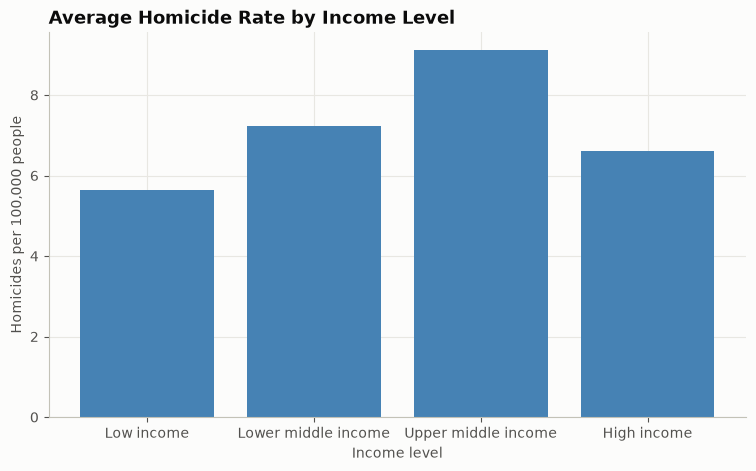

,avg_rate
income_level,
Low income,5.63
Lower middle income,7.23
Upper middle income,9.11
High income,6.61


In [425]:
# Visualization 1: average homicide rate for each income level
# SQL join: homicide_rates (web scraped) + gdp_per_capita (API)
avg_by_income = pd.read_sql_query("""
SELECT g.income_level, AVG(h.homicide_rate_per_100k) AS avg_rate
FROM homicide_rates h
JOIN gdp_per_capita g ON g.alpha_2 = h.alpha_2 AND g.year = 2024
GROUP BY g.income_level
""", conn)

# Put the income levels in order from poorest to richest
avg_by_income = avg_by_income.set_index('income_level').loc[income_order]

plt.figure(figsize=(9, 5))
plt.bar(avg_by_income.index, avg_by_income['avg_rate'], color='steelblue')
plt.title('Average Homicide Rate by Income Level')
plt.xlabel('Income level')
plt.ylabel('Homicides per 100,000 people')
plt.show()

avg_by_income.round(2)

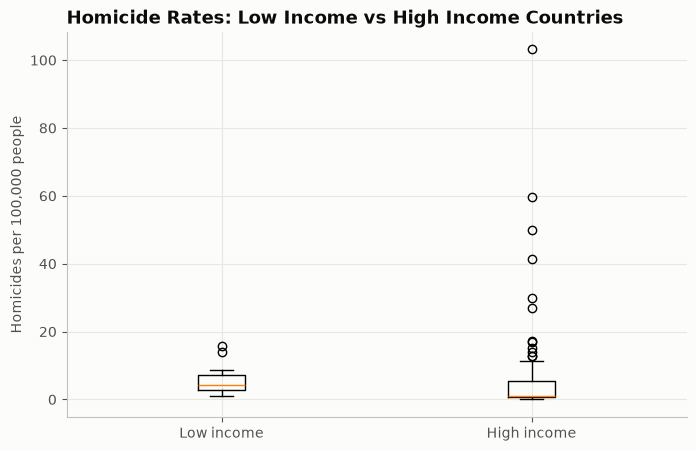

Low income  - average: 5.63, median: 4.22
High income - average: 6.61, median: 1.04


In [426]:
# Visualization 2: lowest income vs highest income countries
# SQL join: homicide_rates (web scraped) + gdp_per_capita (API)
low_vs_high = pd.read_sql_query("""
SELECT g.income_level, h.homicide_rate_per_100k
FROM homicide_rates h
JOIN gdp_per_capita g ON g.alpha_2 = h.alpha_2 AND g.year = 2024
WHERE g.income_level IN ('Low income', 'High income')
""", conn)

low_rates = low_vs_high[low_vs_high['income_level'] == 'Low income']['homicide_rate_per_100k']
high_rates = low_vs_high[low_vs_high['income_level'] == 'High income']['homicide_rate_per_100k']

# A box plot shows the middle 50% of the countries as a box and the median as a line
plt.figure(figsize=(8, 5))
plt.boxplot([low_rates, high_rates])
plt.xticks([1, 2], ['Low income', 'High income'])
plt.title('Homicide Rates: Low Income vs High Income Countries')
plt.ylabel('Homicides per 100,000 people')
plt.show()

print(f"Low income  - average: {low_rates.mean():.2f}, median: {low_rates.median():.2f}")
print(f"High income - average: {high_rates.mean():.2f}, median: {high_rates.median():.2f}")

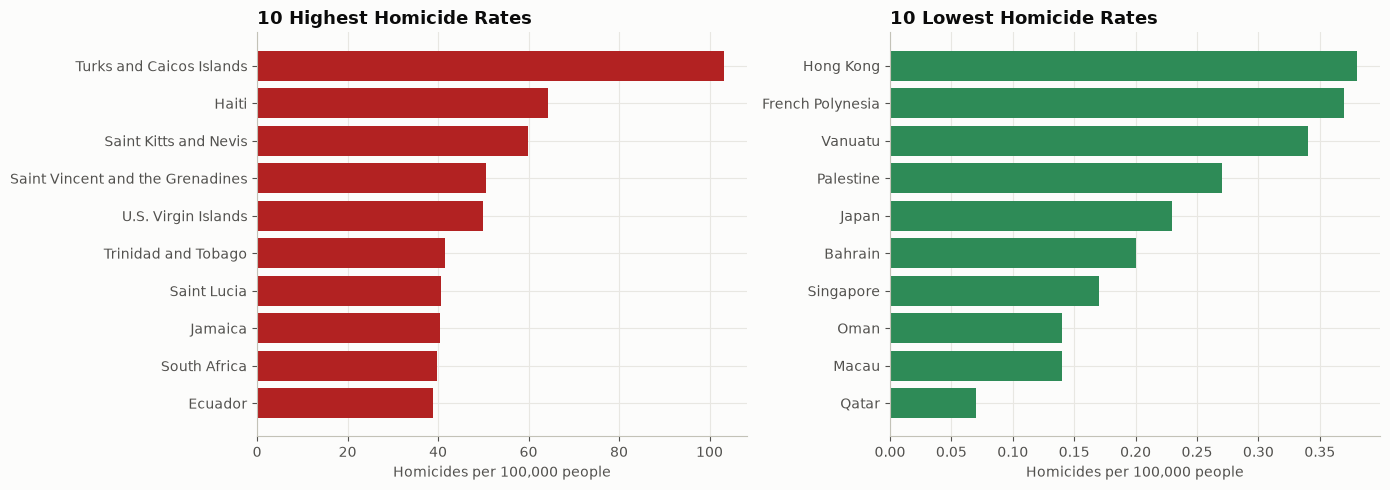

Highest:
                        location  homicide_rate_per_100k        income_level
        Turks and Caicos Islands                  103.15         High income
                           Haiti                   64.34 Lower middle income
           Saint Kitts and Nevis                   59.77         High income
Saint Vincent and the Grenadines                   50.69 Upper middle income
             U.S. Virgin Islands                   49.86         High income
             Trinidad and Tobago                   41.52         High income
                     Saint Lucia                   40.61 Upper middle income
                         Jamaica                   40.36 Upper middle income
                    South Africa                   39.72 Upper middle income
                         Ecuador                   38.94 Upper middle income

Lowest:
        location  homicide_rate_per_100k        income_level
           Qatar                    0.07         High income
           Ma

In [427]:
# Visualization 3: the 10 highest and 10 lowest homicide rates
# SQL join: homicide_rates (web scraped) + gdp_per_capita (API)
# Locations with a rate of zero are left out using the zero_rate flag from Milestone 3
rates_with_income = pd.read_sql_query("""
SELECT h.location, h.homicide_rate_per_100k, g.income_level
FROM homicide_rates h
JOIN gdp_per_capita g ON g.alpha_2 = h.alpha_2 AND g.year = 2024
WHERE h.zero_rate = 0
ORDER BY h.homicide_rate_per_100k
""", conn)

lowest_10 = rates_with_income.head(10)
highest_10 = rates_with_income.tail(10)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

ax1.barh(highest_10['location'], highest_10['homicide_rate_per_100k'], color='firebrick')
ax1.set_title('10 Highest Homicide Rates')
ax1.set_xlabel('Homicides per 100,000 people')

ax2.barh(lowest_10['location'], lowest_10['homicide_rate_per_100k'], color='seagreen')
ax2.set_title('10 Lowest Homicide Rates')
ax2.set_xlabel('Homicides per 100,000 people')

plt.tight_layout()
plt.show()

# Show the income level of each country in the two charts
print("Highest:")
print(highest_10.iloc[::-1].to_string(index=False))
print("\nLowest:")
print(lowest_10.to_string(index=False))

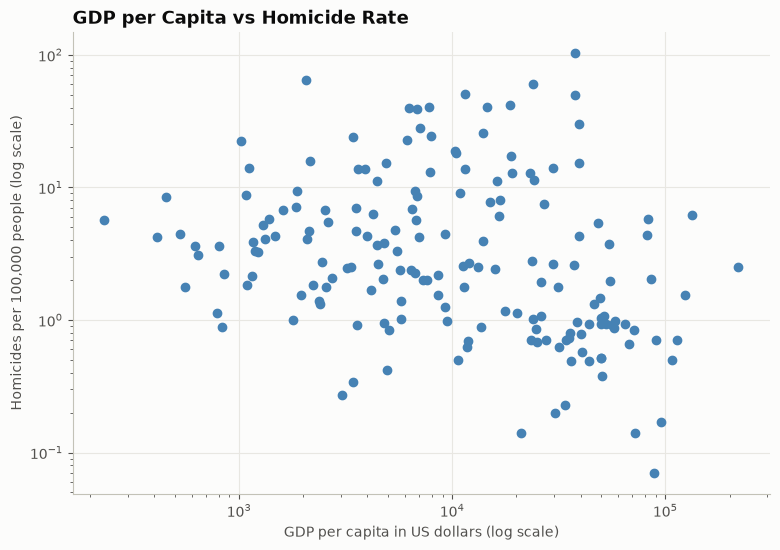

In [428]:
# Visualization 4: GDP per capita vs homicide rate
# SQL join: homicide_rates (web scraped) + gdp_per_capita (API)
# The GDP is matched to the same year as the homicide rate
gdp_vs_homicide = pd.read_sql_query("""
SELECT h.location, h.homicide_rate_per_100k, g.gdp_per_capita_usd
FROM homicide_rates h
JOIN gdp_per_capita g ON g.alpha_2 = h.alpha_2 AND g.year = h.year
WHERE g.gdp_per_capita_usd IS NOT NULL AND h.zero_rate = 0
""", conn)

plt.figure(figsize=(9, 6))
plt.scatter(gdp_vs_homicide['gdp_per_capita_usd'], gdp_vs_homicide['homicide_rate_per_100k'], color='steelblue')
# Both values range from very small to very large, so a log scale spreads the points out
plt.xscale('log')
plt.yscale('log')
plt.title('GDP per Capita vs Homicide Rate')
plt.xlabel('GDP per capita in US dollars (log scale)')
plt.ylabel('Homicides per 100,000 people (log scale)')
plt.show()

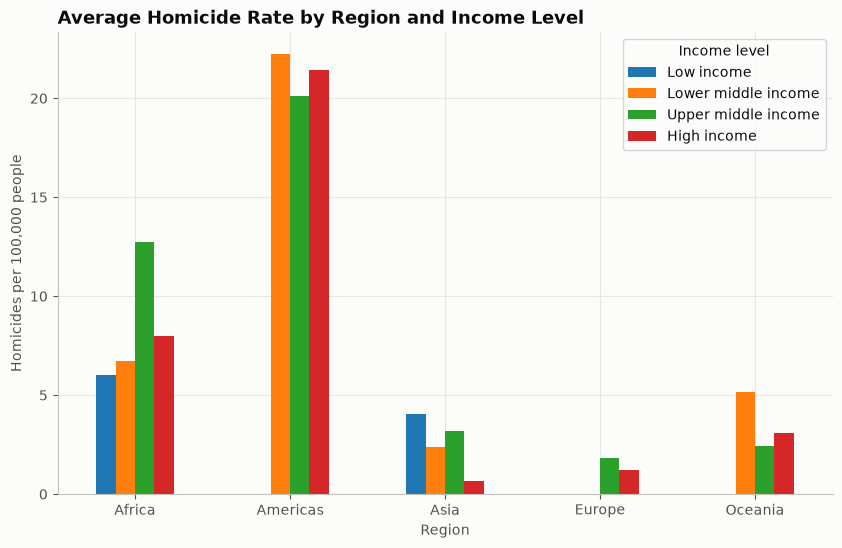

income_level,Low income,Lower middle income,Upper middle income,High income
region,,,,
Africa,6.03,6.71,12.75,7.97
Americas,NaN,22.23,20.14,21.45
Asia,4.03,2.37,3.18,0.65
Europe,NaN,NaN,1.84,1.22
Oceania,NaN,5.13,2.45,3.06


In [429]:
# Visualization 5: average homicide rate by region and income level
# SQL join across all three tables: homicide_rates (web scraped) + countries (CSV) + gdp_per_capita (API)
region_income = pd.read_sql_query("""
SELECT c.region, g.income_level, AVG(h.homicide_rate_per_100k) AS avg_rate
FROM homicide_rates h
JOIN countries c      ON c.alpha_2 = h.alpha_2
JOIN gdp_per_capita g ON g.alpha_2 = h.alpha_2 AND g.year = 2024
GROUP BY c.region, g.income_level
""", conn)

# Turn the rows into a table: one row per region, one column per income level
region_table = region_income.pivot(index='region', columns='income_level', values='avg_rate')
region_table = region_table[income_order]

region_table.plot(kind='bar', figsize=(10, 6))
plt.title('Average Homicide Rate by Region and Income Level')
plt.xlabel('Region')
plt.ylabel('Homicides per 100,000 people')
plt.xticks(rotation=0)
plt.legend(title='Income level')
plt.show()

region_table.round(2)

## Summary
Visualizing bringing this data all together was pretty eye opening. I didn't see any correlation between homicide rates and income but there also was one concern I noticed related to this all. And that is that I do not entirely trust the reporting. Theres are government reported homicide rates and in areas with known conflicts currently like Ukraine and Palestine they were significantly lower than I was expecting. This leads me to beleive that many deaths are unreported especially in areas with active issues or lower income.

## What did I learn?

After taking the data from the three sources including CSV file format, web scraping from a web site, and using HTTP requests to interact with an API. I was able to combine the data based on the ISO-3166 country naming standards and begin to investage the sources all together. I did not really need any major transformations to the data as I previously said it already has an ISO standard so much of this was already cleanly formatted and ready to use. That being said I mostly made column naming changes and ensured missing records were included (I didn't find any); So no changes should effect the results. No real assumptions were needed other than the expectation that a country should being reporting its homicide rates correctly and also provide accurate GDP data. I retrieved the country list from a git repository which is probably the least credible data source but this was also the least important data and I was able to verify its accuracy based on the joins done in the database queries. The homicide rates come from Wikipedia, although I have been told in the past concerns with its reliability I found that the editors retreived the data from the United Nations Office on Drugs and Crime. Lastly the worldbank stores the data for the GDP's of the countries of the world. Across the world this data is anonymous and mostly provided by governments themselves so it is reasonable to believe that it is ethically sourced. The only somewhat unethical thing about this data is its misrepresentation. I believe this data is being purposefully misrepresented around the world and I don't really have a valid fix for this. Much more in depth analysis on war ridden areas may need required like comparing difference in year census calculations to see where the actual numbers lie not what we are told. Other than that I was pleasently surprised to know that other areas seem to not have a direct correlation between income and homicide rates. Lower income areas had a slightly higher homicide rate but the outliers were not nearly as extreme.